In [17]:
%pip install scikit-learn

Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.
Ignoring fixed x limits to fulfill fixed data aspect with adjustable data limits.


                                            location   latitude  longitude
0  Rua de Passos Manuel, Bairro Batalha - Poveiro...  41.146716  -8.605413
1  Rua de Sá da Bandeira, 706, Bairro Bolhão, Bai...  41.146726  -8.609518
2  Beco São Macário, 34, Palácio de Cristal - Gal...  41.150814  -8.628757
3  Rua de Tomás Gonzaga, Miragaia - Virtudes, Ced...  41.142544  -8.619062
4           Aldoar - Foz do Douro - Nevogilde, Porto  41.164703  -8.662367

Total de pontos válidos: 1900
          latitude    longitude
count  1900.000000  1900.000000
mean     41.153734    -8.626565
std       0.020315     0.029657
min      41.018823    -8.693281
25%      41.148887    -8.651545
50%      41.155902    -8.621900
75%      41.164703    -8.605277
max      41.228660    -8.513624


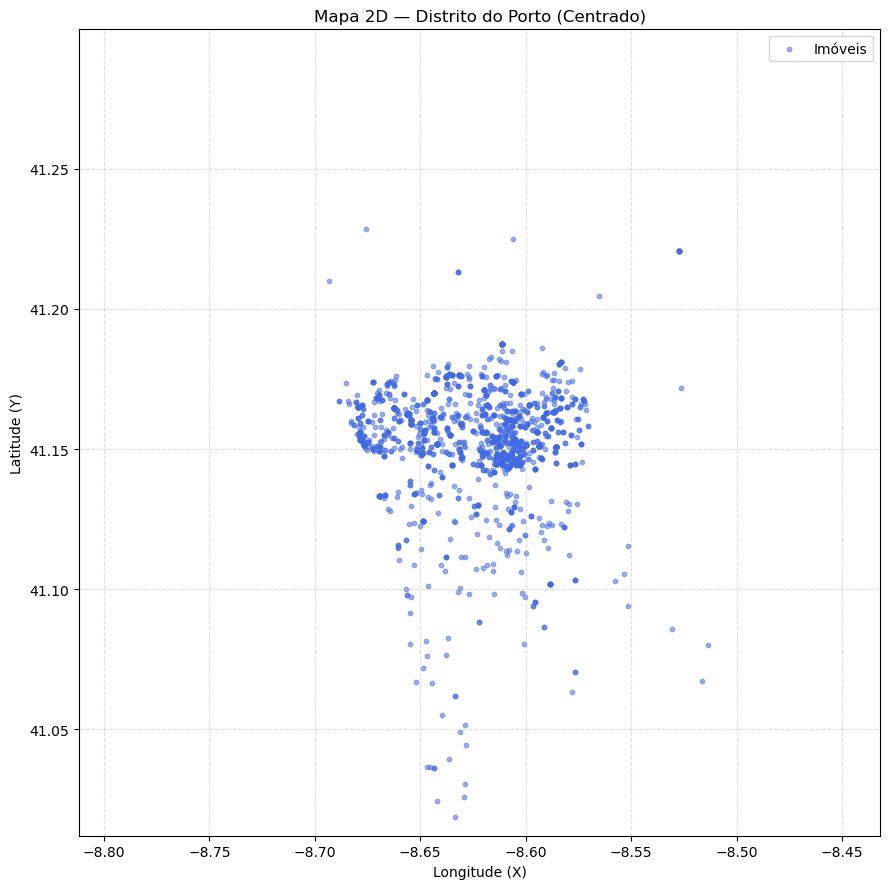

In [12]:
### Desenha o mapa 2D do distrito do Porto com base em coordenadas geográficas (latitude/longitude) de imóveis.


import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# 1. Ler o CSV com separador padrão ',' (ignora linhas corrompidas se existirem)
df_raw = pd.read_csv('porto_district_all_geocoded.csv', sep=',', on_bad_lines='skip')

# Mostrar as primeiras 5 linhas das colunas relevantes para confirmar a leitura
print(df_raw[['location', 'latitude', 'longitude']].head())

# 2. Converter para número sem restringir a [-90, 90] (caso estejam em metros/outra escala)
df = df_raw.copy()
for col in ['latitude', 'longitude']:
  df[col] = pd.to_numeric(
      df[col].astype(str).str.replace(',', '.'), errors='coerce'
  )

# Remover apenas valores nulos (NaN) ou zeros exatos
df = df.dropna(subset=['latitude', 'longitude'])
df = df[(df['latitude'] != 0) & (df['longitude'] != 0)]

print(f'\nTotal de pontos válidos: {len(df)}')

if df.empty:
  print(
      'AVISO: As colunas latitude/longitude estão vazias ou sem números'
      ' válidos neste CSV.'
  )
else:
  print(df[['latitude', 'longitude']].describe())

  # 3. Calcular o elemento central (mediana)
  lat_centro = df['latitude'].median()
  lon_centro = df['longitude'].median()

  # 4. Distância máxima ao centro para garantir que TODOS os pontos aparecem
  margem = 1.05
  max_dx = max((df['longitude'] - lon_centro).abs().max() * margem, 1e-5)
  max_dy = max((df['latitude'] - lat_centro).abs().max() * margem, 1e-5)

  # 5. Criar o mapa 2D
  fig, ax = plt.subplots(figsize=(9, 9))
  ax.scatter(
      df['longitude'],
      df['latitude'],
      s=10,
      color='royalblue',
      alpha=0.5,
      label='Imóveis',
  )
  #ax.scatter(
  #    lon_centro,
  #   lat_centro,
  #    color='crimson',
  #    marker='X',
  #    s=120,
  #   zorder=5,
  #   label='Centro',
  #)

  # 6. Centrar o enquadramento no elemento central
  ax.set_xlim(lon_centro - max_dx, lon_centro + max_dx)
  ax.set_ylim(lat_centro - max_dy, lat_centro + max_dy)

  # Ajusta proporção geográfica se estiver em graus; caso contrário usa proporção 1:1
  if -90 <= lat_centro <= 90:
    ax.set_aspect(1 / np.cos(np.radians(lat_centro)), adjustable='datalim')
  else:
    ax.set_aspect('equal', adjustable='datalim')

  ax.set_title('Mapa 2D — Distrito do Porto (Centrado)')
  ax.set_xlabel('Longitude (X)')
  ax.set_ylabel('Latitude (Y)')
  ax.grid(True, linestyle='--', alpha=0.4)
  ax.legend()

  plt.tight_layout()
  plt.show()

In [15]:
#### Tratamento de dados
# se n tiver id unico n é um dado válido. Segundo dado descartado. Deve ter um contador do numero de vezes q aconteceu
# municipality só vai servir para preencher latidude & longitude.
# operation não é relevante para o nosso estudo, checkamos se é comprar para garantir, se não for é descartado. Deve ter um contador do numero de vezes q aconteceu
# url não é relevante para o nosso estudo
# title não é relevante para o nosso estudo
# price_eur não pode ser menor que 0, se for é descartado. Se for vazio, NaN, ou não for número é descartado. Deve ter um contador do numero de vezes q aconteceu
# area_m2 não pode ser menor que 0, se for é descartado. Se for vazio, NaN, ou não for número é descartado. Deve ter um contador do numero de vezes q aconteceu
# location não é relevante para o nosso estudo
# latitude não pode ser menor que -90 ou maior que 90. Se for, for vazio, NaN, ou não for número é usada a mediana dos dados com municipality igual. Deve ter um contador do numero de vezes q aconteceu
# longitude não pode ser menor que -180 ou maior que 180, se for é descartado. Se for, for vazio, NaN, ou não for número é usada a mediana dos dados com municipality igual. Deve ter um contador do numero de vezes q aconteceu 
# bedrooms não pode ser menor que 0, se for é descartado. Se for vazio, NaN, ou não for número é descartado, usa-se a typology sem T para preencher. Deve ter um contador do numero de vezes q aconteceu
# bathrooms não pode ser menor que 0, se for é descartado. Se for vazio, NaN, ou não for numero é descartado. Deve ter um contador do numero de vezes q aconteceu
# typology não é relevante para o nosso estudo. Vai ser usado para preencher bedrooms.
# property_type não pode ser diferente de house ou apartment, se for é descartado. Se for vazio, NaN, ou não for string é descartado. Deve ter um contador do numero de vezes q aconteceu
# floor não pode ser menor que 0, se for, se for vazio, NaN, ou não for número é colocado 0 se for casa, se for apartment 1. Deve ter um contador do numero de vezes q aconteceu
# num_floors não pode ser menor que 0, se for, se for vazio, NaN, ou não for número é colocado 1 se for casa ou apartment. Deve ter um contador do numero de vezes q aconteceu
# has_garage tem de ser booleano, se for vazio, NaN, ou não for booleano é colocado False. Deve ter um contador do numero de vezes q aconteceu. Passar para inteiro (1/0) em seguida
# has_garden tem de ser booleano, se for vazio, NaN, ou não for booleano é colocado False. Deve ter um contador do numero de vezes q aconteceu. Passar para inteiro (1/0) em seguida
# scraped_at não é relevante para o nosso estudo
# matched_address não é relevante para o nosso estudo
# geocode_status nao é relevante para o nosso estudo.


####
# id 
# municipality	
# operation	
# url	
# title	
# price_eur	!
# area_m2	!
# location	
# latitude	!
# longitude	!
# bedrooms	-!
# bathrooms	
# typology	--
# property_type	!
# floor	
# num_floors	
# has_garage	
# has_garden	
# scraped_at	
# matched_address	
# geocode_status



## Uteis
# price_eur	
# area_m2	
# latitude	
# longitude	
# bedrooms	
# bathrooms	
# typology	acho q n
# property_type	
# floor	
# num_floors	
# has_garage	
# has_garden	



import numpy as np
import pandas as pd

# Carregar dataset original
df = pd.read_csv("porto_district_all_geocoded.csv")
df_clean = df.copy()

# Dicionário para guardar todos os contadores exigidos
contadores = {}
linhas_iniciais = len(df_clean)

# Padronizar strings vazias ou apenas com espaços para np.nan
df_clean = df_clean.replace(r"^\s*$", np.nan, regex=True)

# ---------------------------------------------------------
# 1. ID ÚNICO (descarta nulos/vazios e a 2ª+ ocorrência)
# ---------------------------------------------------------
if "id" in df_clean.columns:
  mask_id_invalido = df_clean["id"].isna() | df_clean["id"].duplicated(
      keep="first"
  )
  contadores["id_invalido_ou_duplicado_descartados"] = int(
      mask_id_invalido.sum()
  )
  df_clean = df_clean[~mask_id_invalido].copy()
else:
  # Caso a coluna 'id' não exista no CSV, verifica pelo índice
  mask_id_invalido = df_clean.index.isna() | df_clean.index.duplicated(
      keep="first"
  )
  contadores["id_invalido_ou_duplicado_descartados"] = int(
      mask_id_invalido.sum()
  )
  df_clean = df_clean[~mask_id_invalido].copy()

# ---------------------------------------------------------
# 2. OPERATION (garantir que é comprar / sale)
# ---------------------------------------------------------
op_norm = df_clean["operation"].astype(str).str.strip().str.lower()
# Aceita 'comprar' (ou 'sale' caso o dataset esteja em inglês)
mask_op_valida = df_clean["operation"].notna() & op_norm.isin(
    ["comprar", "sale"]
)
contadores["operation_nao_comprar_descartados"] = int((~mask_op_valida).sum())
df_clean = df_clean[mask_op_valida].copy()

# ---------------------------------------------------------
# 3. PRICE_EUR (não pode ser < 0, vazio, NaN ou não-número)
# ---------------------------------------------------------
price_num = pd.to_numeric(df_clean["price_eur"], errors="coerce")
mask_price_valido = price_num.notna() & (price_num >= 0)
contadores["price_eur_invalido_descartados"] = int((~mask_price_valido).sum())
df_clean = df_clean[mask_price_valido].copy()
df_clean["price_eur"] = price_num[mask_price_valido]

# ---------------------------------------------------------
# 4. AREA_M2 (não pode ser < 0, vazio, NaN ou não-número)
# ---------------------------------------------------------
area_num = pd.to_numeric(df_clean["area_m2"], errors="coerce")
mask_area_valida = area_num.notna() & (area_num >= 0)
contadores["area_m2_invalido_descartados"] = int((~mask_area_valida).sum())
df_clean = df_clean[mask_area_valida].copy()
df_clean["area_m2"] = area_num[mask_area_valida]

# ---------------------------------------------------------
# 5. PROPERTY_TYPE (tem de ser string 'house' ou 'apartment')
#    Executado antes de floor/num_floors para garantir tipos válidos
# ---------------------------------------------------------
eh_string = df_clean["property_type"].apply(lambda x: isinstance(x, str))
prop_norm = df_clean["property_type"].astype(str).str.strip().str.lower()
mask_prop_valida = eh_string & prop_norm.isin(["house", "apartment"])
contadores["property_type_invalido_descartados"] = int(
    (~mask_prop_valida).sum()
)
df_clean = df_clean[mask_prop_valida].copy()
df_clean["property_type"] = prop_norm[mask_prop_valida]

# ---------------------------------------------------------
# 6. BEDROOMS (< 0 descarta; vazio/NaN/não-número tenta preencher com typology sem 'T', senão descarta)
# ---------------------------------------------------------
bed_num = pd.to_numeric(df_clean["bedrooms"], errors="coerce")

# 6a. Descartar imediatamente se for número menor que 0
mask_bed_negativo = bed_num.notna() & (bed_num < 0)
contadores["bedrooms_menor_que_0_descartados"] = int(mask_bed_negativo.sum())
df_clean = df_clean[~mask_bed_negativo].copy()
bed_num = bed_num[~mask_bed_negativo]

# 6b. Preencher vazios/NaN/não-números usando typology sem 'T'
mask_bed_ausente = bed_num.isna()
typ_sem_t = pd.to_numeric(
    df_clean.loc[mask_bed_ausente, "typology"]
    .astype(str)
    .str.strip()
    .str.upper()
    .str.lstrip("T"),
    errors="coerce",
)
# Só aceita valores válidos >= 0 extraídos da typology
typ_sem_t = typ_sem_t.where(typ_sem_t >= 0, np.nan)
bed_num.loc[mask_bed_ausente] = typ_sem_t

contadores["bedrooms_preenchidos_com_typology"] = int(typ_sem_t.notna().sum())

# 6c. Descartar linhas que continuam sem bedrooms válido após tentar typology
mask_bed_final_invalido = bed_num.isna()
contadores["bedrooms_sem_valor_nem_typology_descartados"] = int(
    mask_bed_final_invalido.sum()
)
contadores["bedrooms_total_ocorrencias"] = (
    contadores["bedrooms_menor_que_0_descartados"]
    + contadores["bedrooms_preenchidos_com_typology"]
    + contadores["bedrooms_sem_valor_nem_typology_descartados"]
)

df_clean = df_clean[~mask_bed_final_invalido].copy()
df_clean["bedrooms"] = bed_num[~mask_bed_final_invalido]

# ---------------------------------------------------------
# 7. BATHROOMS (não pode ser < 0, vazio, NaN ou não-número)
# ---------------------------------------------------------
bath_num = pd.to_numeric(df_clean["bathrooms"], errors="coerce")
mask_bath_valido = bath_num.notna() & (bath_num >= 0)
contadores["bathrooms_invalido_descartados"] = int((~mask_bath_valido).sum())
df_clean = df_clean[mask_bath_valido].copy()
df_clean["bathrooms"] = bath_num[mask_bath_valido]

# ---------------------------------------------------------
# 8. LATITUDE (< -90, > 90, vazio, NaN ou não-número -> mediana do municipality)
# ---------------------------------------------------------
lat_num = pd.to_numeric(df_clean["latitude"], errors="coerce")
mask_lat_invalida = lat_num.isna() | (lat_num < -90) | (lat_num > 90)
contadores["latitude_corrigidos_mediana"] = int(mask_lat_invalida.sum())

lat_num[mask_lat_invalida] = np.nan
df_clean["latitude"] = lat_num
df_clean["latitude"] = df_clean["latitude"].fillna(
    df_clean.groupby("municipality")["latitude"].transform("median")
)
# Fallback caso algum municipality inteiro não tenha coordenadas válidas
df_clean["latitude"] = df_clean["latitude"].fillna(
    df_clean["latitude"].median()
)

# ---------------------------------------------------------
# 9. LONGITUDE (< -180 ou > 180 descarta; vazio, NaN ou não-número -> mediana do municipality)
# ---------------------------------------------------------
lon_num = pd.to_numeric(df_clean["longitude"], errors="coerce")

# 9a. Fora dos limites [-180, 180] -> descartado
mask_lon_fora_limites = lon_num.notna() & ((lon_num < -180) | (lon_num > 180))
contadores["longitude_fora_limites_descartados"] = int(
    mask_lon_fora_limites.sum()
)
df_clean = df_clean[~mask_lon_fora_limites].copy()
lon_num = lon_num[~mask_lon_fora_limites]

# 9b. Vazio, NaN ou não-número -> mediana por municipality
mask_lon_ausente = lon_num.isna()
contadores["longitude_corrigidos_mediana"] = int(mask_lon_ausente.sum())
contadores["longitude_total_ocorrencias"] = (
    contadores["longitude_fora_limites_descartados"]
    + contadores["longitude_corrigidos_mediana"]
)

df_clean["longitude"] = lon_num
df_clean["longitude"] = df_clean["longitude"].fillna(
    df_clean.groupby("municipality")["longitude"].transform("median")
)
df_clean["longitude"] = df_clean["longitude"].fillna(
    df_clean["longitude"].median()
)

# ---------------------------------------------------------
# 10. FLOOR (< 0, vazio, NaN ou não-número -> 0 se house, 1 se apartment)
# ---------------------------------------------------------
floor_num = pd.to_numeric(df_clean["floor"], errors="coerce")
mask_floor_invalido = floor_num.isna() | (floor_num < 0)
contadores["floor_corrigidos"] = int(mask_floor_invalido.sum())

floor_num[mask_floor_invalido & (df_clean["property_type"] == "house")] = 0
floor_num[mask_floor_invalido & (df_clean["property_type"] == "apartment")] = 1
df_clean["floor"] = floor_num

# ---------------------------------------------------------
# 11. NUM_FLOORS (< 0, vazio, NaN ou não-número -> 1 se house ou apartment)
# ---------------------------------------------------------
num_floors_num = pd.to_numeric(df_clean["num_floors"], errors="coerce")
mask_num_floors_invalido = num_floors_num.isna() | (num_floors_num < 0)
contadores["num_floors_corrigidos"] = int(mask_num_floors_invalido.sum())

num_floors_num[mask_num_floors_invalido] = 1
df_clean["num_floors"] = num_floors_num

# ---------------------------------------------------------
# 12 & 13. HAS_GARAGE e HAS_GARDEN (booleano válido, senão False)
# ---------------------------------------------------------
mapa_booleanos_validos = {
    True: True,
    False: False,
    1: True,
    0: False,
    1.0: True,
    0.0: False,
    "true": True,
    "false": False,
    "1": True,
    "0": False,
    "1.0": True,
    "0.0": False,
}

for col_bool in ["has_garage", "has_garden"]:
  serie_norm = df_clean[col_bool].apply(
      lambda x: x.strip().lower() if isinstance(x, str) else x
  )
  eh_booleano_valido = serie_norm.isin(mapa_booleanos_validos.keys()) & (
      df_clean[col_bool].notna()
  )
  contadores[f"{col_bool}_invalido_colocado_false"] = int(
      (~eh_booleano_valido).sum()
  )

  df_clean[col_bool] = serie_norm.map(mapa_booleanos_validos).fillna(False).astype(bool)

  ## Booleano para inteiro (1/0) no df_clean

  for col_bool in ["has_garage", "has_garden"]:
    serie_norm = df_clean[col_bool].apply(
      lambda x: x.strip().lower() if isinstance(x, str) else x
  )
  eh_booleano_valido = serie_norm.isin(mapa_booleanos_validos.keys()) & (
      df_clean[col_bool].notna()
  )
  contadores[f"{col_bool}_invalido_colocado_false"] = int(
      (~eh_booleano_valido).sum()
  )

  # Fica logo como 1 (True) e 0 (False) no df_clean
  df_clean[col_bool] = (
      serie_norm.map(mapa_booleanos_validos).fillna(False).astype(int)
  )

# ---------------------------------------------------------
# 14. REMOVER COLUNAS IRRELEVANTES PARA O ESTUDO
# ---------------------------------------------------------
colunas_irrelevantes = [
    "municipality",
    "operation",
    "url",
    "title",
    "location",
    "typology",
    "scraped_at",
    "matched_address",
    "geocode_status",
]
df_clean = df_clean.drop(
    columns=[c for c in colunas_irrelevantes if c in df_clean.columns]
)

# ---------------------------------------------------------
# VALIDAÇÃO FINAL E RELATÓRIO DE CONTADORES
# ---------------------------------------------------------
assert df_clean.isna().sum().sum() == 0, "Erro: Ainda existem valores NaN!"

print(f"Linhas iniciais: {linhas_iniciais}")
print(f"Linhas finais válidas (df_clean): {len(df_clean)}")
print(f"Total de linhas descartadas: {linhas_iniciais - len(df_clean)}\n")

print("=== CONTADORES DE TRATAMENTO ===")
for regra, total in contadores.items():
  print(f"- {regra}: {total}")

print("\nColunas finais:", df_clean.columns.tolist())

Linhas iniciais: 1900
Linhas finais válidas (df_clean): 1888
Total de linhas descartadas: 12

=== CONTADORES DE TRATAMENTO ===
- id_invalido_ou_duplicado_descartados: 0
- operation_nao_comprar_descartados: 0
- price_eur_invalido_descartados: 0
- area_m2_invalido_descartados: 0
- property_type_invalido_descartados: 0
- bedrooms_menor_que_0_descartados: 0
- bedrooms_preenchidos_com_typology: 0
- bedrooms_sem_valor_nem_typology_descartados: 0
- bedrooms_total_ocorrencias: 0
- bathrooms_invalido_descartados: 12
- latitude_corrigidos_mediana: 0
- longitude_fora_limites_descartados: 0
- longitude_corrigidos_mediana: 0
- longitude_total_ocorrencias: 0
- floor_corrigidos: 432
- num_floors_corrigidos: 1712
- has_garage_invalido_colocado_false: 0
- has_garden_invalido_colocado_false: 0

Colunas finais: ['id', 'price_eur', 'area_m2', 'latitude', 'longitude', 'bedrooms', 'bathrooms', 'property_type', 'floor', 'num_floors', 'has_garage', 'has_garden']


In [18]:
#### separar training e test set, standerizar ambos

from sklearn.model_selection import train_test_split

# 1. Separar as características (X) do preço (y)
X = df_clean.drop(columns=["price_eur", "id"], errors="ignore")
y = df_clean["price_eur"]

# 2. Dividir em 80% treino e 20% teste
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Treino: {len(X_train)} casas | Teste: {len(X_test)} casas")



Treino: 1510 casas | Teste: 378 casas
